# Bài 02: Bản chất Ảnh số — Kênh màu, Quy ước Chiều (HWC vs NCHW), Nội suy và Histogram

## 1. Mục tiêu học tập
- Hiểu cấu trúc vật lý và toán học của ảnh số: `pixel` (điểm ảnh), độ phân giải không gian (`spatial resolution`), độ sâu bit (`bit depth`) và số kênh màu (`Grayscale`, `RGB`, `BGR`, `RGBA`).
- Nắm vững quy ước chuyển đổi thứ tự chiều giữa **OpenCV/Matplotlib (`HWC`)** và **PyTorch (`CHW` / `NCHW`)**.
- Chuyển đổi chính xác ảnh giữa kiểu số nguyên `uint8 [0, 255]` và số thực `float32 [0.0, 1.0]`.
- Thực hành các phép biến đổi hình học và cường độ sáng: `Resize`, `Crop`, `Interpolation` (`NEAREST`, `LINEAR`, `CUBIC`), `Histogram`, `Brightness` (độ sáng) và `Contrast` (độ tương phản).
- Với mỗi phép biến đổi: Quan sát **Ảnh gốc → Phép biến đổi → Ảnh kết quả → Giải thích tác dụng và giới hạn**.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 01 (`NumPy array`, `shape`, `dtype`, `broadcasting`).

## 3. Thời gian học dự kiến
- Khoảng **2.0 – 2.5 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Một mô hình mạng nơ-ron yêu cầu ảnh đầu vào phải có kích thước cố định `(Batch, 3, 32, 32)` ở hệ màu `RGB` và giá trị nằm trong `[0.0, 1.0]`. Trong khi đó, ảnh đọc từ camera công nghiệp bằng OpenCV lại có kích thước `(480, 640, 3)` ở hệ màu `BGR` và bị thiếu sáng. Bạn cần xây dựng bước tiền xử lý chuẩn xác mà không làm biến dạng thông tin.

## 5. Giải thích trực quan: Các Không gian Kênh và Thứ tự Chiều
1. **Grayscale (Ảnh đa mức xám)**: `1` kênh duy nhất `(H, W)` hoặc `(H, W, 1)`. Công thức chuẩn ITU-R BT.601 chuyển từ `RGB` sang `Gray`:
   $$Y = 0.299 R + 0.587 G + 0.114 B$$
   *(Mắt người nhạy nhất với màu xanh lá `G`, nên hệ số của `G` lớn nhất là `0.587`)*.
2. **`RGB` vs `BGR`**: Cùng chứa 3 kênh Đỏ, Lá, Dương nhưng `OpenCV` xếp thứ tự `[Blue, Green, Red]` do lịch sử phần cứng camera đời đầu.
3. **Kênh `Alpha` (`RGBA`, 4 kênh)**: Kênh thứ 4 biểu diễn độ đục (`opacity`: `0` là trong suốt hoàn toàn, `255` hoặc `1.0` là đặc hoàn toàn). Công thức trộn ảnh tiền cảnh $I_{fg}$ lên nền $I_{bg}$ (**Alpha Blending**):
   $$I_{\text{out}} = \alpha \cdot I_{fg} + (1 - \alpha) \cdot I_{bg}, \quad \alpha \in [0, 1]$$
4. **Quy ước chiều `HWC` vs `CHW` và `NCHW`**:
   - Thư viện hiển thị và xử lý ảnh (`OpenCV`, `Pillow`, `Matplotlib`): lưu từng điểm ảnh cạnh nhau → **`HWC`** `(Height, Width, Channels)`.
   - `PyTorch`: lưu từng mặt phẳng kênh liên tiếp nhau để tối ưu phép tích chập trên bộ nhớ đệm → **`CHW`** `(Channels, Height, Width)`, và khi gom theo lô là **`NCHW`** `(Batch_size, Channels, Height, Width)`.

## 6. Thuật ngữ mới & Giải thích Keyword
| Keyword | Nghĩa tiếng Việt | Nhóm | Kiểu / Giá trị | Vai trò, Ảnh hưởng & Lưu ý lỗi |
|---|---|---|---|---|
| `interpolation` | Nội suy điểm ảnh khi Resize | Dữ liệu | `cv2.INTER_NEAREST`, `INTER_LINEAR`, `INTER_CUBIC`, `INTER_AREA` | Xác định cách tính giá trị pixel tại tọa độ mới. **Quy tắc**: Khi resize **ảnh thường** dùng `INTER_LINEAR` (phóng to) hoặc `INTER_AREA` (thu nhỏ chống răng cưa); nhưng khi resize **mặt nạ nhãn (`segmentation mask`)** **BẮT BUỘC dùng `INTER_NEAREST`** để không tạo ra số thập phân làm hỏng ID nhãn lớp! |
| `histogram` | Biểu đồ tần suất mức sáng | Dữ liệu | Mảng 1D `(bins,)` | Đếm số lượng pixel ở từng mức sáng `0..255`. Giúp phát hiện ảnh bị cháy sáng (dồn về `255`), thiếu sáng (dồn về `0`) hoặc kém tương phản (co cụm ở giữa). |
| `alpha` (Contrast gain) & `beta` (Brightness bias) | Hệ số tương phản & Độ lệch sáng | Dữ liệu | Số thực ($\alpha > 0$, $\beta \in \mathbb{R}$) | Trong biến đổi tuyến tính $I'(y,x) = \text{clip}(\alpha \cdot I(y,x) + \beta, 0, 255)$: Tăng $\alpha > 1$ làm dãn histogram (tăng tương phản); tăng $\beta > 0$ dịch toàn bộ histogram sang phải (tăng sáng). |


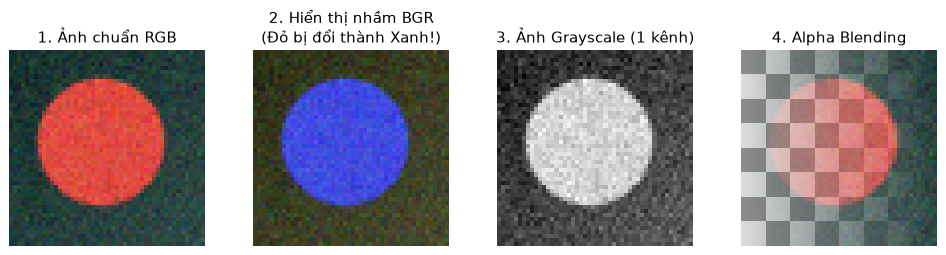

In [1]:
# Cell 1: Khởi tạo và minh họa chuyển đổi RGB <-> BGR, Grayscale, RGBA Alpha Blending
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.utils import set_seed

set_seed(42)
ds = generate_synthetic_shapes_dataset(num_samples=4, image_size=48, seed=42)
img_rgb = ds["images"][0]  # Hình tròn màu đỏ cam trên nền tối

# Chuyển sang BGR (như khi đọc bằng cv2.imread) và Grayscale
img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

# Tạo kênh Alpha (trong suốt dần từ trái sang phải) và trộn lên nền caro trắng-xám
h, w, _ = img_rgb.shape
alpha_channel = np.tile(np.linspace(0.0, 1.0, w, dtype=np.float32), (h, 1))[..., None]
yy, xx = np.mgrid[0:h, 0:w]
checker_bg = (((yy // 6 + xx // 6) % 2) * 80 + 140).astype(np.float32)[..., None]
img_blended = np.clip(alpha_channel * img_rgb.astype(np.float32) + (1.0 - alpha_channel) * checker_bg, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
axes[0].imshow(img_rgb)
axes[0].set_title("1. Ảnh chuẩn RGB")
axes[1].imshow(img_bgr)
axes[1].set_title("2. Hiển thị nhầm BGR\n(Đỏ bị đổi thành Xanh!)")
axes[2].imshow(img_gray, cmap="gray")
axes[2].set_title("3. Ảnh Grayscale (1 kênh)")
axes[3].imshow(img_blended)
axes[3].set_title("4. Alpha Blending")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [2]:
# Cell 2: Chuyển đổi HWC (uint8) <-> CHW / NCHW (float32) cho PyTorch
# Bước 1: Ảnh đơn (H, W, C) uint8 [0..255] -> Tensor (C, H, W) float32 [0.0..1.0]
tensor_chw = torch.from_numpy(img_rgb).permute(2, 0, 1).to(torch.float32) / 255.0

# Bước 2: Lô ảnh (N, H, W, C) -> Batch Tensor (N, C, H, W)
batch_hwc = ds["images"]
batch_nchw = torch.from_numpy(batch_hwc).permute(0, 3, 1, 2).to(torch.float32) / 255.0

# Bước 3: Chuyển ngược từ Tensor (C, H, W) về NumPy (H, W, C) uint8 để hiển thị
reconstructed_rgb = (tensor_chw.permute(1, 2, 0).numpy() * 255.0).round().clip(0, 255).astype(np.uint8)

print(f"NumPy đơn ảnh (HWC)  : shape={img_rgb.shape}, dtype={img_rgb.dtype}, range=[{img_rgb.min()}, {img_rgb.max()}]")
print(f"PyTorch đơn ảnh (CHW): shape={tuple(tensor_chw.shape)}, dtype={tensor_chw.dtype}, range=[{tensor_chw.min():.3f}, {tensor_chw.max():.3f}]")
print(f"PyTorch Batch (NCHW) : shape={tuple(batch_nchw.shape)}")
assert np.array_equal(img_rgb, reconstructed_rgb), "Chuyển đổi hai chiều phải bảo toàn tuyệt đối giá trị pixel!"


NumPy đơn ảnh (HWC)  : shape=(48, 48, 3), dtype=uint8, range=[0, 255]
PyTorch đơn ảnh (CHW): shape=(3, 48, 48), dtype=torch.float32, range=[0.000, 1.000]
PyTorch Batch (NCHW) : shape=(4, 3, 48, 48)


Các giá trị nhãn trong mask gốc            : [0 2]
Resize mask bằng INTER_LINEAR (BỊ TẠO NHÃN GIẢ 1!): [0 1 2]
Resize mask bằng INTER_NEAREST (CHÍNH XÁC) : [0 2]


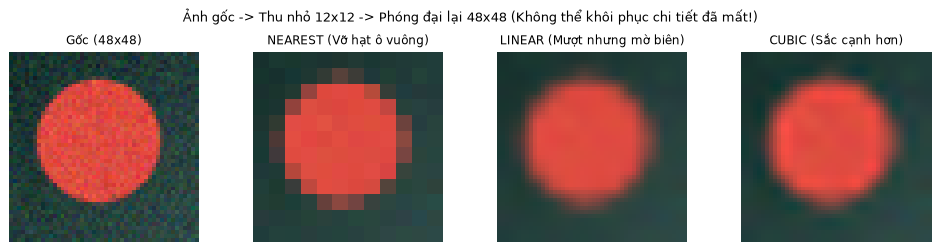

In [3]:
# Cell 3: Resize & Interpolation — Tác dụng và Giới hạn khi phóng to / thu nhỏ ảnh và mask
# Thu nhỏ ảnh 48x48 xuống 12x12 (mất thông tin tần số cao) rồi phóng to lại 48x48 bằng 3 kiểu nội suy
small_12 = cv2.resize(img_rgb, (12, 12), interpolation=cv2.INTER_AREA)
up_nearest = cv2.resize(small_12, (48, 48), interpolation=cv2.INTER_NEAREST)
up_linear = cv2.resize(small_12, (48, 48), interpolation=cv2.INTER_LINEAR)
up_cubic = cv2.resize(small_12, (48, 48), interpolation=cv2.INTER_CUBIC)

# Kiểm chứng lỗi nghiêm trọng nếu dùng INTER_LINEAR trên mặt nạ nhãn (mask có nhãn 0 và 2)
mask_gt = np.zeros((24, 24), dtype=np.uint8)
mask_gt[6:18, 6:18] = 2  # Nhãn lớp 2
mask_wrong = cv2.resize(mask_gt, (48, 48), interpolation=cv2.INTER_LINEAR)
mask_correct = cv2.resize(mask_gt, (48, 48), interpolation=cv2.INTER_NEAREST)
print("Các giá trị nhãn trong mask gốc            :", np.unique(mask_gt))
print("Resize mask bằng INTER_LINEAR (BỊ TẠO NHÃN GIẢ 1!):", np.unique(mask_wrong))
print("Resize mask bằng INTER_NEAREST (CHÍNH XÁC) :", np.unique(mask_correct))

fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
for ax, im, title in zip(
    axes,
    [img_rgb, up_nearest, up_linear, up_cubic],
    ["Gốc (48x48)", "NEAREST (Vỡ hạt ô vuông)", "LINEAR (Mượt nhưng mờ biên)", "CUBIC (Sắc cạnh hơn)"],
):
    ax.imshow(im)
    ax.set_title(title, fontsize=9.5)
    ax.axis("off")
plt.suptitle("Ảnh gốc -> Thu nhỏ 12x12 -> Phóng đại lại 48x48 (Không thể khôi phục chi tiết đã mất!)", fontsize=10.5)
plt.tight_layout()
plt.show()


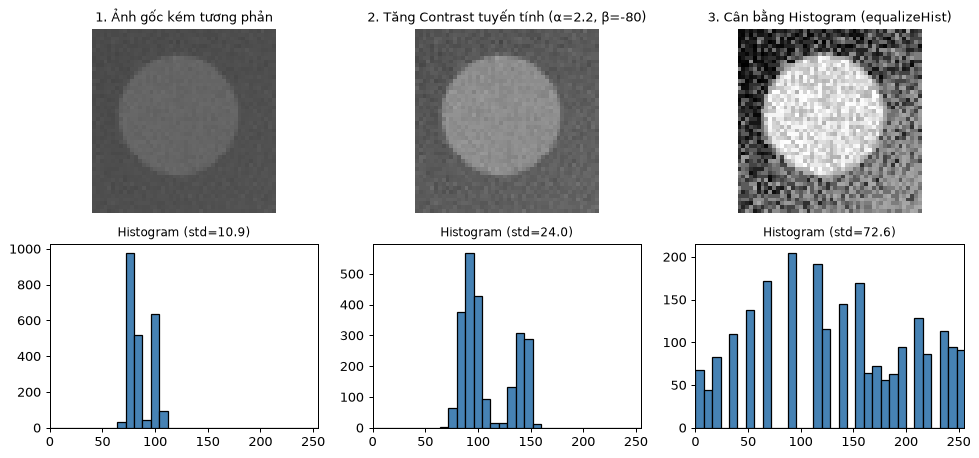

In [4]:
# Cell 4: Thí nghiệm thay đổi Brightness, Contrast và Cân bằng Histogram (Histogram Equalization)
# Tạo phiên bản ảnh thiếu sáng & kém tương phản (nén vào dải [60..110])
low_contrast = np.clip(img_gray.astype(np.float32) * 0.35 + 60.0, 0, 255).astype(np.uint8)

# Cách 1: Biến đổi tuyến tính với alpha=2.2 (tăng contrast), beta=-80 (chỉnh lại điểm đen)
linear_stretched = np.clip(low_contrast.astype(np.float32) * 2.2 - 80.0, 0, 255).astype(np.uint8)

# Cách 2: Cân bằng biểu đồ tần suất tự động (Histogram Equalization)
hist_eq = cv2.equalizeHist(low_contrast)

fig, axes = plt.subplots(2, 3, figsize=(11, 5.2))
variants = [
    (low_contrast, "1. Ảnh gốc kém tương phản"),
    (linear_stretched, "2. Tăng Contrast tuyến tính (α=2.2, β=-80)"),
    (hist_eq, "3. Cân bằng Histogram (equalizeHist)"),
]
for col, (im, title) in enumerate(variants):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(title, fontsize=10)
    axes[0, col].axis("off")

    axes[1, col].hist(im.ravel(), bins=32, range=(0, 256), color="steelblue", edgecolor="black")
    axes[1, col].set_title(f"Histogram (std={im.std():.1f})", fontsize=9.5)
    axes[1, col].set_xlim(0, 255)
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- **Về Resize & Interpolation (Cell 3)**: Một khi ảnh đã bị thu nhỏ xuống `12x12`, thông tin tần số cao đã mất vĩnh viễn. Phóng to lại lên `48x48` chỉ là ước lượng nội suy giữa các điểm lân cận. Đặc biệt, kết quả in ra chứng minh nếu dùng `INTER_LINEAR` trên mask nhãn `[0, 2]`, các điểm biên bị nội suy thành số `1` (tạo ra nhãn lớp giả không tồn tại!).
- **Về Histogram (Cell 4)**: Ảnh kém tương phản có biểu đồ co cụm ở giữa (`60..110`). Sau khi kéo dãn tuyến tính hoặc `equalizeHist`, biểu đồ trải rộng ra toàn dải `0..255`, độ lệch chuẩn (`std`) tăng vọt giúp vật thể nổi bật rõ rệt trên nền. Giới hạn của `equalizeHist` toàn cục là có thể khuếch đại luôn cả nhiễu ở vùng nền phẳng.

## 13. Lỗi thường gặp và cách sửa
1. **Dùng `cv2.resize(..., width, height)` nhầm với `shape = (height, width)`**: Lưu ý `cv2.resize(img, dsize=(new_W, new_H))` nhận **`(width, height)`**, ngược với thứ tự `(height, width)` của `img.shape[:2]`!
2. **Quên chia `255.0` khi chuyển sang `float32`**: Nếu để tensor `float32` mang giá trị `0.0..255.0` đưa vào mạng có sẵn hoặc hàm `plt.imshow(float_img)`, ảnh sẽ bị bão hòa trắng xóa hoặc làm nổ gradient.

## 14. Bài tập tự làm
- **Cơ bản**: Viết hàm `letterbox_resize(img, target_size=64)` thay đổi kích thước ảnh có chiều `(H, W)` bất kỳ (ví dụ `(30, 60, 3)`) về hình vuông `(64, 64, 3)` mà **giữ nguyên tỉ lệ khung hình (aspect ratio)** bằng cách đệm viền xám (`114`).
- **Trung cấp**: Thực hiện phép hiệu chỉnh Gamma (**Gamma Correction**): $I_{\text{out}} = 255 \times (I_{\text{in}} / 255)^\gamma$ với $\gamma = 0.5$ (làm sáng vùng tối) và $\gamma = 2.0$ (làm tối vùng trung gian), vẽ đồ thị so sánh.
- **Nâng cao**: So sánh cân bằng histogram toàn cục (`cv2.equalizeHist`) với cân bằng histogram thích nghi giới hạn độ tương phản **CLAHE** (`cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))`) trên ảnh có độ sáng không đều.

## 15. Gợi ý và Lời giải
- *Gợi ý*: Trong `letterbox_resize`, hệ số co giãn là `scale = min(target_size / H, target_size / W)`. Xem code lời giải đầy đủ bên dưới.


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 02
# 1. Cơ bản: Letterbox resize bảo toàn tỉ lệ khung hình
def letterbox_resize(img: np.ndarray, target_size: int = 64, pad_val: int = 114) -> np.ndarray:
    h, w = img.shape[:2]
    scale = min(target_size / h, target_size / w)
    new_w, new_h = int(round(w * scale)), int(round(h * scale))
    resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    canvas = np.full((target_size, target_size, 3), pad_val, dtype=np.uint8)
    top = (target_size - new_h) // 2
    left = (target_size - new_w) // 2
    canvas[top : top + new_h, left : left + new_w] = resized
    return canvas

rect_img = cv2.resize(img_rgb, (60, 30))  # Ảnh chữ nhật H=30, W=60
lb_img = letterbox_resize(rect_img, target_size=64)
print("[Cơ bản] Ảnh gốc:", rect_img.shape, "-> Sau letterbox:", lb_img.shape)

# 2. Trung cấp: Gamma Correction
norm_gray = img_gray.astype(np.float32) / 255.0
gamma_05 = np.clip((norm_gray ** 0.5) * 255.0, 0, 255).astype(np.uint8)
gamma_20 = np.clip((norm_gray ** 2.0) * 255.0, 0, 255).astype(np.uint8)
print(f"[Trung cấp] Mean gốc={img_gray.mean():.1f}, Gamma 0.5={gamma_05.mean():.1f}, Gamma 2.0={gamma_20.mean():.1f}")

# 3. Nâng cao: CLAHE chống khuếch đại nhiễu quá mức
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
img_clahe = clahe.apply(low_contrast)
print(f"[Nâng cao] Std sau equalizeHist={hist_eq.std():.1f} vs CLAHE={img_clahe.std():.1f}")


[Cơ bản] Ảnh gốc: (30, 60, 3) -> Sau letterbox: (64, 64, 3)
[Trung cấp] Mean gốc=74.7, Gamma 0.5=134.6, Gamma 2.0=25.2
[Nâng cao] Std sau equalizeHist=72.6 vs CLAHE=35.0


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã phân biệt rõ `RGB`, `BGR`, `Grayscale`, `RGBA` và chuyển đổi thành thạo `HWC <-> NCHW`.
- [x] Hiểu nguyên tắc chọn `interpolation` cho ảnh thường và cho mặt nạ nhãn (`INTER_NEAREST`).
- [x] Sẵn sàng chuyển sang **Bài 03: `03_classical_image_processing.ipynb`**.

## 17. Nguồn tham khảo
- Gonzalez, R. C., & Woods, R. E. (2018), *Digital Image Processing* (4th ed.), Pearson.
- OpenCV Geometric Image Transformations: https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html
